<a href="https://colab.research.google.com/github/GHseyram/Ghana-energy-transition-investment-analytics/blob/main/notebooks/05_ghana_solar_scenario.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ghana Commercial Solar Scenario
## Combining Documented Inputs and Explicit Assumptions

Author: Seyram Amedede

### Purpose
Estimate savings, simple payback and NPV for an illustrative
100 kWp commercial solar installation in Accra.

### Evidence carried forward
- T03: published SLT-LV energy tariff
- FX01: dated USD/GHS reference exchange rate
- Y01: PVGIS Accra generation simulation

### Remaining assumptions
Customer tariff classification, installation cost, maintenance,
self-consumption, degradation, project lifetime and discount rate
remain illustrative.

### Modelling approach
Use Ghana cedis consistently for costs and cash flows.
Translate the illustrative USD installation cost into GHS using
FX01 as a dated scenario assumption.

notebook 03 is unchanged as the original USD reference model.

### Limitations
This is a scenario analysis, not a customer-specific feasibility
study. Unresolved source issues documented in notebook 04 remain
applicable.

In [1]:
import pandas as pd
import json
from urllib.request import urlopen

# Y01: preserved PVGIS simulation
pvgis_url = (
    "https://raw.githubusercontent.com/GHseyram/"
    "Ghana-energy-transition-investment-analytics/main/data/"
    "PVGIS-6.0_GridConnectedPV_5.6037_-0.1870_sarah3_"
    "crystallineSilicon_1kWp_14_8deg_180deg.json"
)

with urlopen(pvgis_url) as response:
    pvgis_data = json.load(response)

annual_yield = (
    pvgis_data["outputs"]["fixed"]["totals"]["E_y"]
    / pvgis_data["inputs"]["pv_module"]["peak_power"]
)

# Documented values carried forward from notebook 04
energy_tariff_ghs = 240.2104 / 100  # T03: GHp to GHS per kWh
exchange_rate = 11.6650             # FX01: GHS per USD

# Illustrative project assumptions
system_size_kwp = 100
installation_cost_usd_per_kwp = 900
self_consumption_rate = 0.90
maintenance_rate = 0.015
project_lifetime_years = 20
annual_degradation_rate = 0.005
real_discount_rate = 0.08

installation_cost_ghs = (
    system_size_kwp
    * installation_cost_usd_per_kwp
    * exchange_rate
)

print(f"PVGIS yield: {annual_yield:,.2f} kWh/kWp/year")
print(f"Energy tariff: GHS {energy_tariff_ghs:.6f}/kWh")
print(f"Illustrative installation cost: GHS {installation_cost_ghs:,.2f}")

PVGIS yield: 1,603.91 kWh/kWp/year
Energy tariff: GHS 2.402104/kWh
Illustrative installation cost: GHS 1,049,850.00


In [2]:
annual_generation_kwh = system_size_kwp * annual_yield

annual_self_consumed_kwh = (
    annual_generation_kwh * self_consumption_rate
)

annual_gross_savings_ghs = (
    annual_self_consumed_kwh * energy_tariff_ghs
)

annual_maintenance_ghs = (
    installation_cost_ghs * maintenance_rate
)

annual_net_savings_ghs = (
    annual_gross_savings_ghs - annual_maintenance_ghs
)

simple_payback_years = (
    installation_cost_ghs / annual_net_savings_ghs
    if annual_net_savings_ghs > 0
    else float("inf")
)

print(f"Annual generation: {annual_generation_kwh:,.0f} kWh")
print(f"Annual on-site use: {annual_self_consumed_kwh:,.1f} kWh")
print(f"Gross savings: GHS {annual_gross_savings_ghs:,.2f}")
print(f"Maintenance: GHS {annual_maintenance_ghs:,.2f}")
print(f"Net savings: GHS {annual_net_savings_ghs:,.2f}")
print(f"Simple payback: {simple_payback_years:.2f} years")

Annual generation: 160,391 kWh
Annual on-site use: 144,351.9 kWh
Gross savings: GHS 346,748.28
Maintenance: GHS 15,747.75
Net savings: GHS 331,000.53
Simple payback: 3.17 years


In [3]:
cash_flow_rows = [{
    "Year": 0,
    "Generation (kWh)": 0,
    "Gross savings (GHS)": 0,
    "Maintenance (GHS)": 0,
    "Net cash flow (GHS)": -installation_cost_ghs,
    "Discounted cash flow (GHS)": -installation_cost_ghs
}]

for year in range(1, project_lifetime_years + 1):
    generation = annual_generation_kwh * (
        (1 - annual_degradation_rate) ** (year - 1)
    )

    gross_savings = (
        generation * self_consumption_rate * energy_tariff_ghs
    )
    net_cash_flow = gross_savings - annual_maintenance_ghs

    cash_flow_rows.append({
        "Year": year,
        "Generation (kWh)": generation,
        "Gross savings (GHS)": gross_savings,
        "Maintenance (GHS)": annual_maintenance_ghs,
        "Net cash flow (GHS)": net_cash_flow,
        "Discounted cash flow (GHS)": (
            net_cash_flow / (1 + real_discount_rate) ** year
        )
    })

ghana_cash_flows = pd.DataFrame(cash_flow_rows)

ghana_npv_ghs = (
    ghana_cash_flows["Discounted cash flow (GHS)"].sum()
)

print(f"Scenario NPV: GHS {ghana_npv_ghs:,.2f}")
ghana_cash_flows.round(2)

Scenario NPV: GHS 2,083,189.03


,Year,Generation (kWh),Gross savings (GHS),Maintenance (GHS),Net cash flow (GHS),Discounted cash flow (GHS)
0,0,0.00,0.00,0.00,-1049850.00,-1049850.00
1,1,160391.00,346748.28,15747.75,331000.53,306481.97
2,2,159589.05,345014.54,15747.75,329266.79,282293.20
3,3,158791.10,343289.46,15747.75,327541.71,260013.17
4,4,157997.14,341573.02,15747.75,325825.27,239491.30
5,5,157207.16,339865.15,15747.75,324117.40,220588.86
6,6,156421.12,338165.82,15747.75,322418.07,203178.08
7,7,155639.02,336475.00,15747.75,320727.25,187141.27
8,8,154860.82,334792.62,15747.75,319044.87,172370.02
9,9,154086.52,333118.66,15747.75,317370.91,158764.47


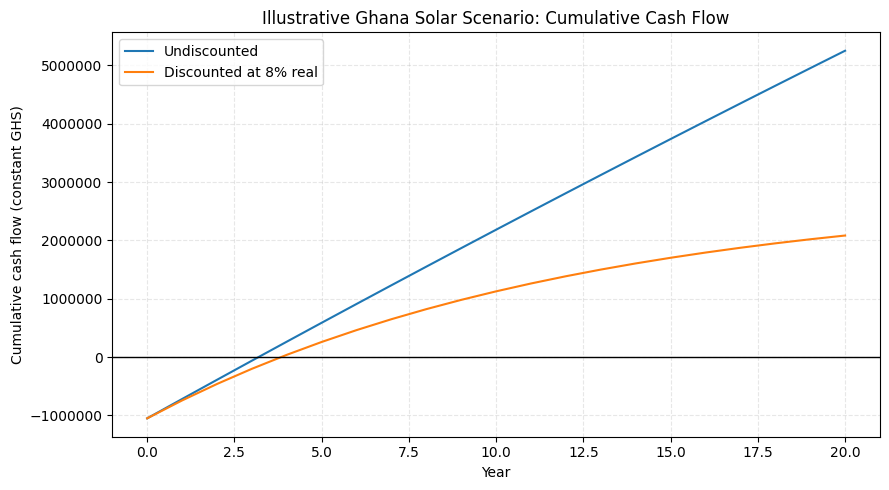

In [4]:
import matplotlib.pyplot as plt

ghana_cash_flows["Cumulative cash flow (GHS)"] = (
    ghana_cash_flows["Net cash flow (GHS)"].cumsum()
)

ghana_cash_flows["Cumulative discounted cash flow (GHS)"] = (
    ghana_cash_flows["Discounted cash flow (GHS)"].cumsum()
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    ghana_cash_flows["Year"],
    ghana_cash_flows["Cumulative cash flow (GHS)"],
    label="Undiscounted"
)

ax.plot(
    ghana_cash_flows["Year"],
    ghana_cash_flows["Cumulative discounted cash flow (GHS)"],
    label=f"Discounted at {real_discount_rate:.0%} real"
)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Illustrative Ghana Solar Scenario: Cumulative Cash Flow")
ax.set_xlabel("Year")
ax.set_ylabel("Cumulative cash flow (constant GHS)")
ax.ticklabel_format(axis="y", style="plain")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
ghana_results = pd.DataFrame({
    "Metric": [
        "Installation cost",
        "First-year gross savings",
        "First-year maintenance",
        "First-year net savings",
        "Simple payback",
        "20-year NPV"
    ],
    "Value": [
        installation_cost_ghs,
        annual_gross_savings_ghs,
        annual_maintenance_ghs,
        annual_net_savings_ghs,
        simple_payback_years,
        ghana_npv_ghs
    ],
    "Unit": [
        "GHS", "GHS/year", "GHS/year",
        "GHS/year", "years", "GHS"
    ]
})

ghana_results.round(2)

,Metric,Value,Unit
0,Installation cost,1049850.00,GHS
1,First-year gross savings,346748.28,GHS/year
2,First-year maintenance,15747.75,GHS/year
3,First-year net savings,331000.53,GHS/year
4,Simple payback,3.17,years
5,20-year NPV,2083189.03,GHS


### Interpretation of the Ghana scenario

The summary above reports the initial investment, first-year
savings, simple payback and 20-year NPV in Ghana cedis.

Simple payback assumes constant first-year net savings.
The NPV calculation instead incorporates annual generation
degradation and discounts year-end cash flows at an illustrative
8% real GHS rate.

The tariff and maintenance cost are held constant in real terms.
This is a modelling assumption, not a forecast of future tariffs
or operating costs.

A positive NPV would indicate that the modelled savings exceed
the initial investment after discounting at the assumed rate.
It would not establish the viability of an actual customer project.

Installation cost, customer classification, self-consumption,
maintenance and financial assumptions still require supporting
evidence. The PVGIS source limitations recorded in notebook 04
also apply.